## Libraries Import

In [68]:
import os

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

## Img input Trial

In [45]:
def read_img(img_path: str):
    img = cv2.imread(img_path)
    plt.figure(figsize=(15, 10))
    plt.imshow(img[..., ::-1])
    return img

## Model Asset and Config the Options

In [46]:
def read_model_assets(
    model_asset_path: str = "/Users/whoami/Documents/Digital-Twin-with-Gesture-configuration-and-Deep-learning-distribute-to-Unity/src/assets/hand_landmarker.task",
):
    base_options = python.BaseOptions(model_asset_path=model_asset_path)
    options = vision.HandLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.IMAGE,
        num_hands=1,
        min_hand_detection_confidence=0.5,
    )
    return options

## Standardize the Image

In [48]:
def formatting_image(img):
    rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_img)
    return mp_image

## Detect hand landmarker

In [60]:
def detect_result(options, mp_image):
    with vision.HandLandmarker.create_from_options(options) as detector:
        detection_result = detector.detect(mp_image)
    return detection_result

## Draw landmarker and connection

In [62]:
def draw_landmarks_on_img(img, detection_result, img_name: str, img_saved_path: str):
    annotated_img = img.copy()
    h, w, _ = annotated_img.shape
    connections = vision.HandLandmarksConnections.HAND_CONNECTIONS

    for hand_landmarks in detection_result.hand_landmarks:
        # Draw skeleton connections
        for connection in connections:
            start = hand_landmarks[connection.start]
            end = hand_landmarks[connection.end]
            cv2.line(
                annotated_img,
                (int(start.x * w), int(start.y * h)),
                (int(end.x * w), int(end.y * h)),
                (0, 255, 0),
                2,
            )

        # Draw landmark keypoints
        for landmark in hand_landmarks:
            cv2.circle(
                annotated_img,
                (int(landmark.x * w), int(landmark.y * h)),
                4,
                (0, 0, 255),
                -1,
            )

    # 5. Plot results
    plt.figure(figsize=(20, 15))
    plt.subplot(121)
    plt.imshow(img[..., ::-1])
    plt.title("Hand Image")
    plt.subplot(122)
    plt.imshow(annotated_img[..., ::-1])
    plt.title("Hand Detection")
    plt.show()
    img_saved_path_with_name = img_saved_path + "/" + img_name
    plt.imsave(img_saved_path_with_name, annotated_img[..., ::-1])

## get world-hand-landmarker

In [64]:
def get_world_hand_landmarker(
    detection_result, output_name: str, output_path: str
) -> dict:
    hands_data = {}
    for idx, world_landmarks in enumerate(detection_result.hand_world_landmarks):
        handedness = detection_result.handedness[idx][0].category_name

        coords_3d = np.array([[lm.x, lm.y, lm.z] for lm in world_landmarks])

        hands_data[handedness] = {
            "wrist": coords_3d[0].tolist(),
            "thumb": coords_3d[1:5].tolist(),
            "index": coords_3d[5:9].tolist(),
            "middle": coords_3d[9:13].tolist(),
            "ring": coords_3d[13:17].tolist(),
            "pinky": coords_3d[17:21].tolist(),
        }

    os.makedirs(output_path, exist_ok=True)
    if not output_name.endswith(".npy"):
        output_name += ".npy"
    output_path_with_name = os.path.join(output_path, output_name)

    np.save(output_path_with_name, hands_data)

    return hands_data

## Processing 

W0000 00:00:1795329453.257654  557166 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795329453.273264  557168 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


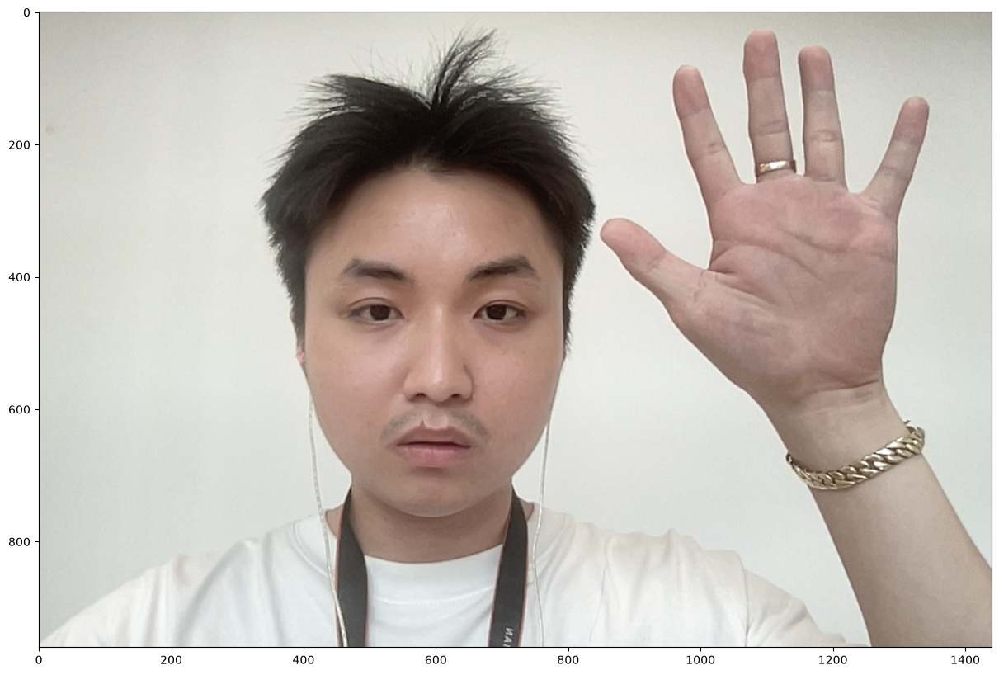

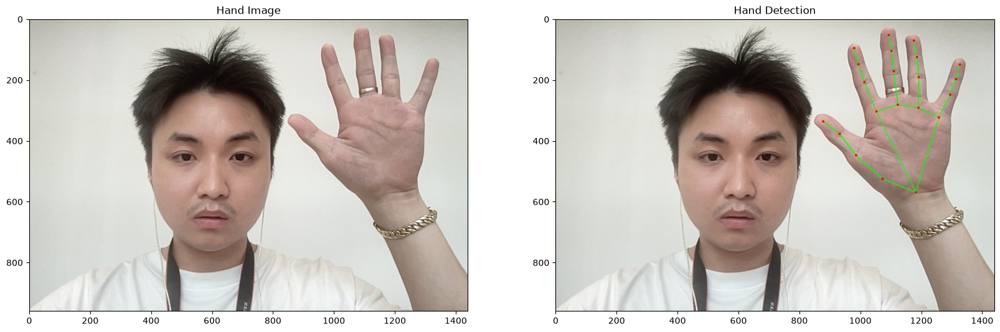

W0000 00:00:1795329454.436273  557193 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795329454.442281  557198 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


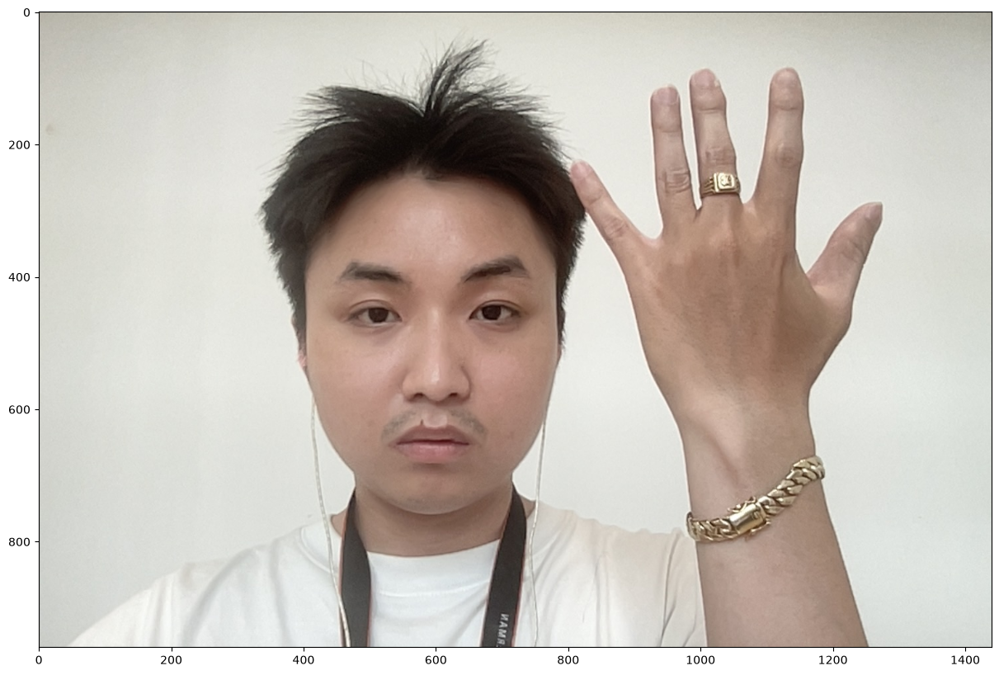

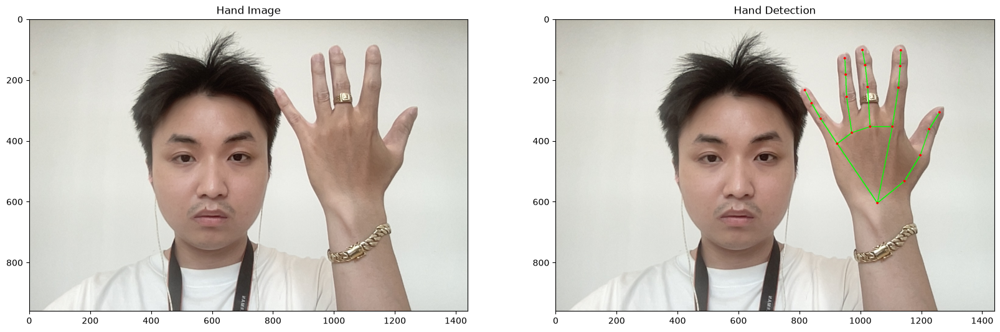

W0000 00:00:1795329455.410059  557225 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795329455.413536  557226 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


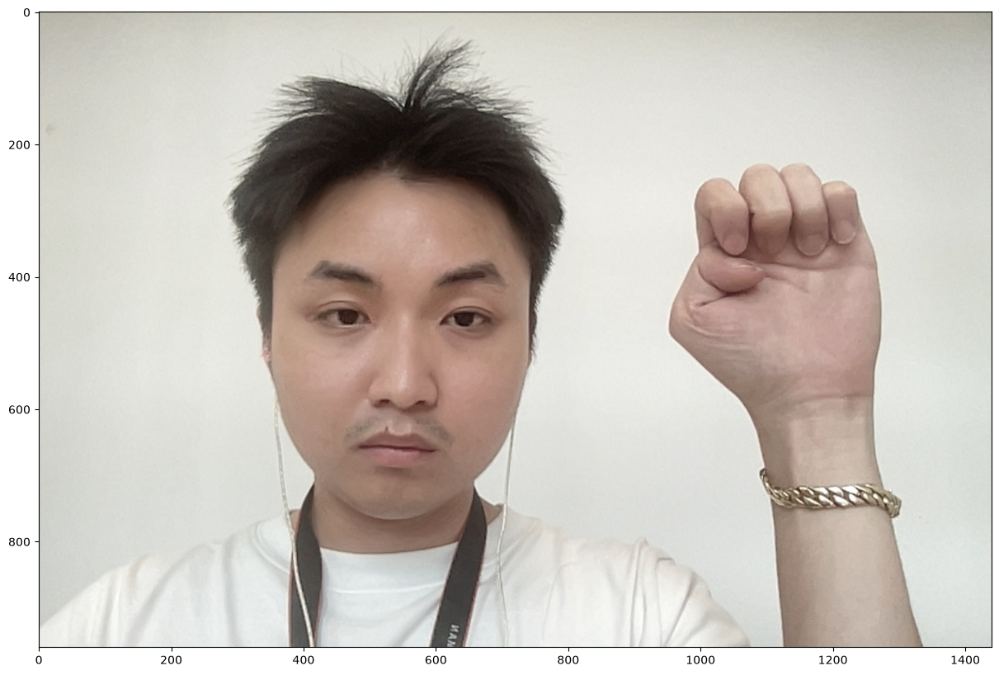

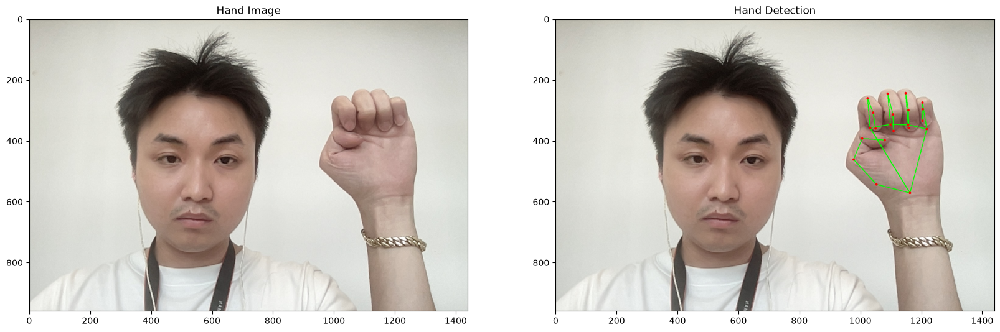

W0000 00:00:1795329456.380198  557244 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795329456.384874  557244 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


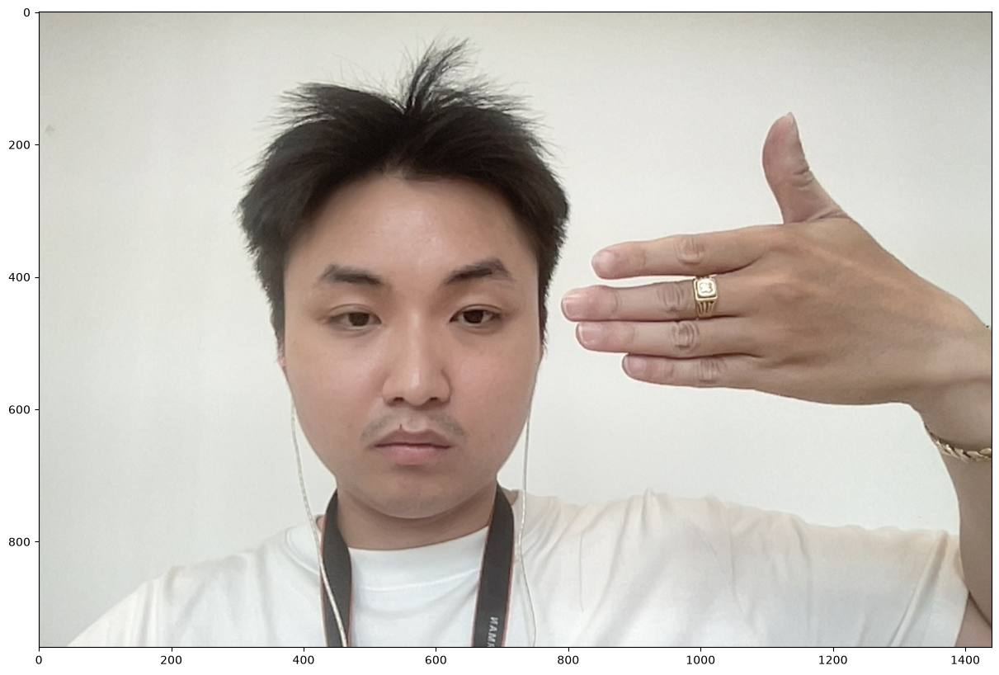

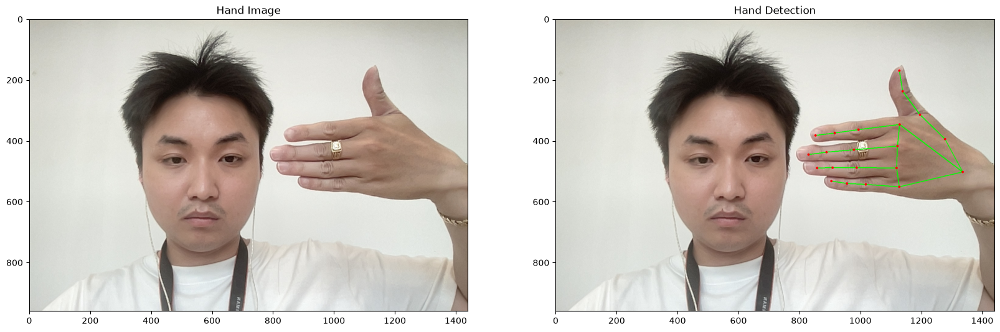

W0000 00:00:1795329457.371110  557284 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795329457.374584  557284 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


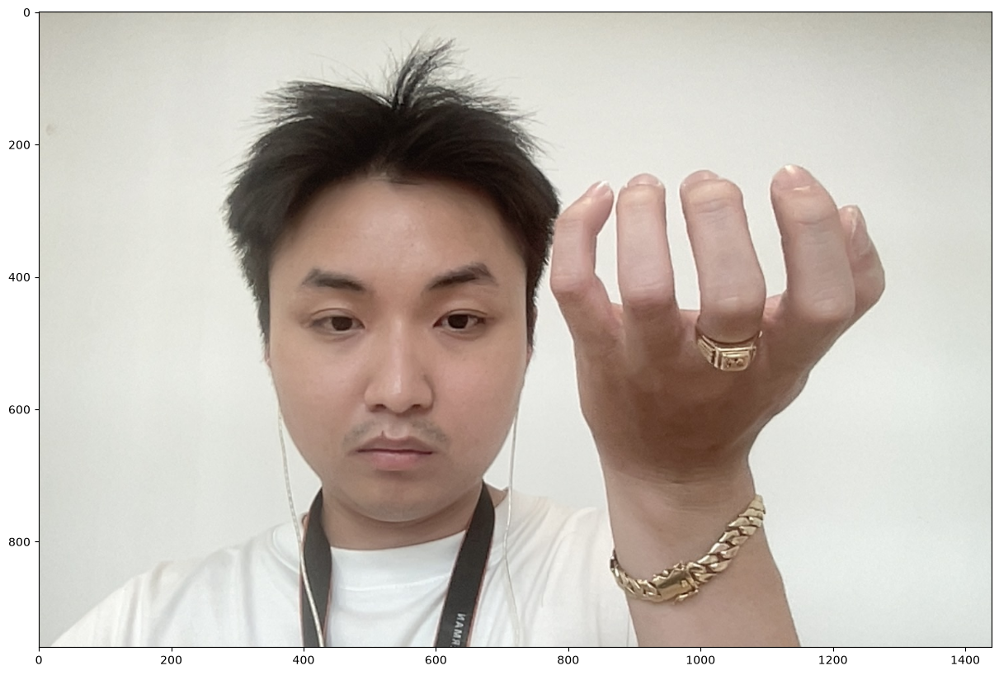

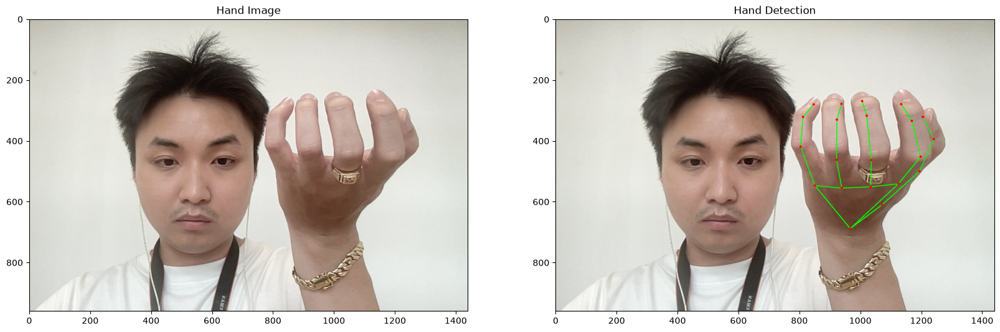

W0000 00:00:1795329458.357739  557295 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795329458.361534  557295 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


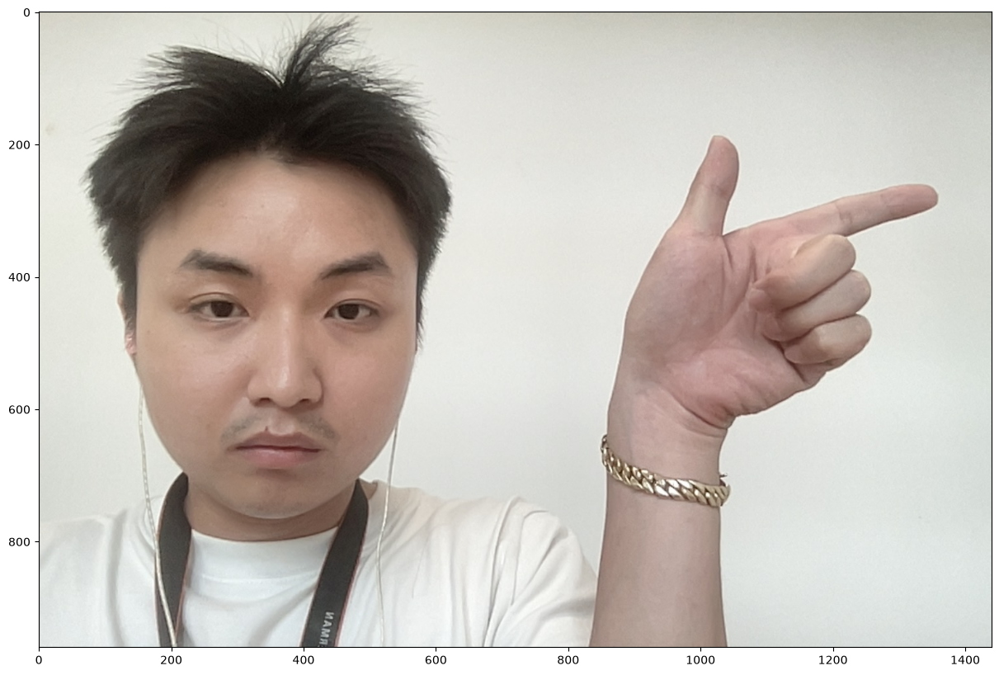

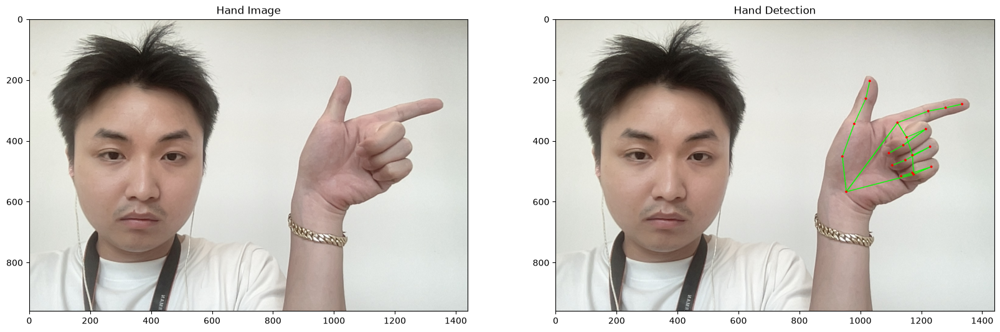

W0000 00:00:1795329459.295664  557338 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795329459.298671  557337 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


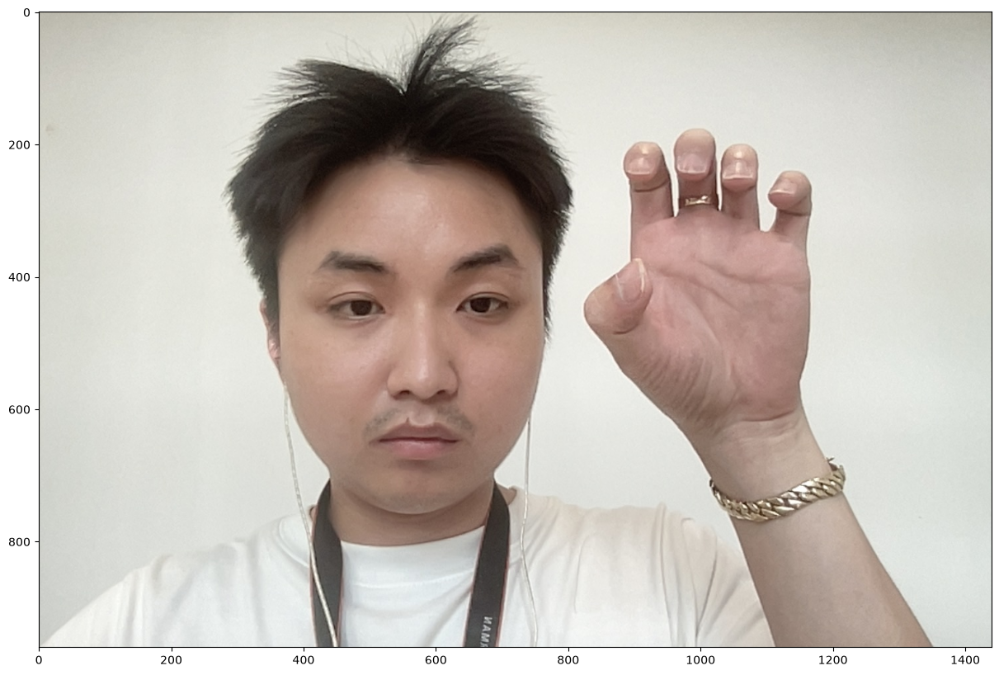

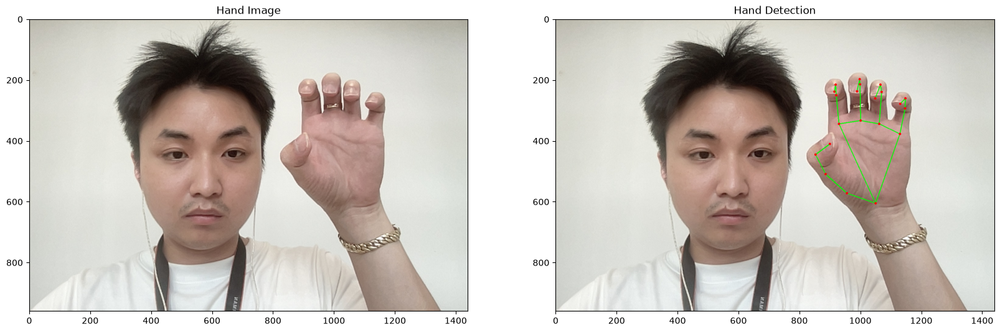

W0000 00:00:1795329460.211137  557360 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795329460.214023  557361 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


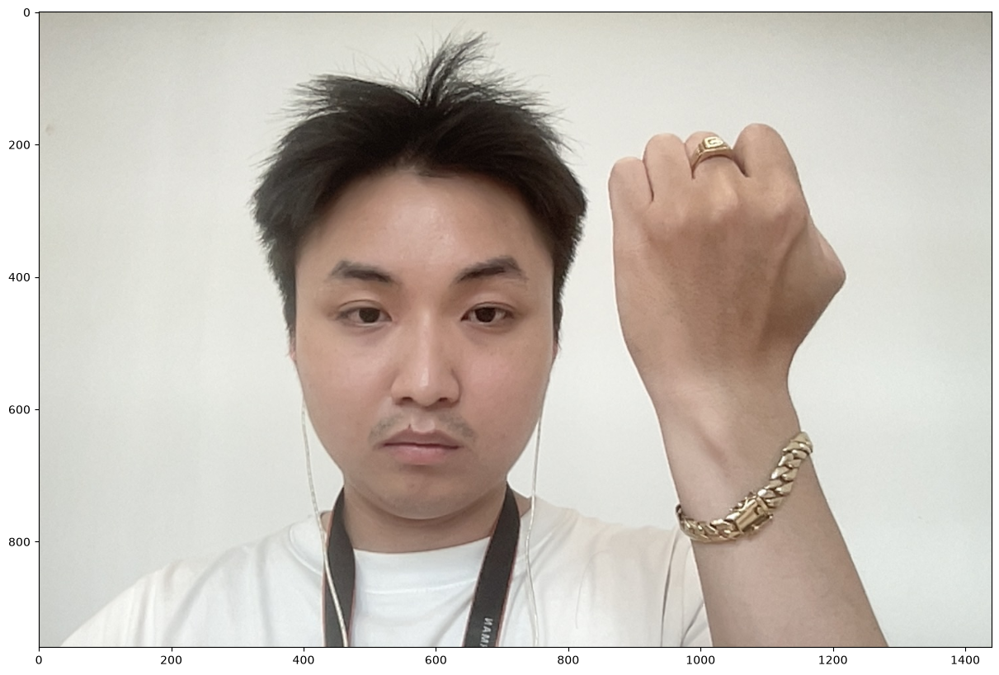

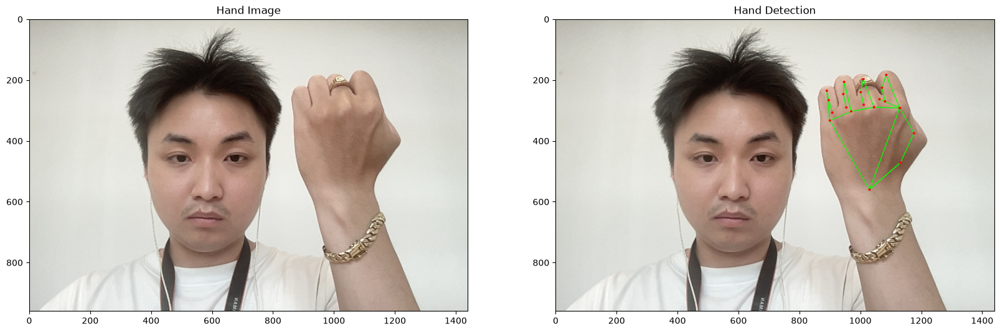

In [67]:
file_path = "img"
files = os.listdir(file_path)

for file in files:
    file_direction = file_path + "/" + file

    # read input file

    img = read_img(img_path=file_direction)
    options = read_model_assets()
    mp_image = formatting_image(img=img)
    detection_result = detect_result(options=options, mp_image=mp_image)
    draw_landmarks = draw_landmarks_on_img(
        img=img,
        detection_result=detection_result,
        img_name=str(file),
        img_saved_path="img-with-landmarks",
    )
    get_world_hand_landmarker(
        detection_result=detection_result,
        output_name=str(file[:-5]),
        output_path="landmarks",
    )